# Phase 3b — Reverse-Causation Check

**Purpose.** The lag sweep in notebook 03 found that the mortgage-rate change is, if anything, **negatively** related to later declines, the opposite of the hypothesis. One possible explanation is that the arrow runs the other way: a cooling housing market may influence later rate decisions, so price momentum would correlate with the rate change that comes **later**.

This notebook tests that direction: does national price momentum **lead** future mortgage-rate changes?

- **National momentum at month t**: the 3-month change of the median county ZHVI, using Train months only.
- **Rate step at month t + k**: the 1-month change of the mortgage rate in percentage points, for leads k = 1 to 18 months.
- **Variant A** uses all rate months. For the latest months this reaches rate data after the end of Train.
- **Variant B** only uses rate months up to the end of Train, so no Embargo or Test period rate enters the check.

The SQL (`sql/004b_reverse_causation.sql`) builds every (momentum, rate step) pair on the server and computes the correlations. This notebook adds the intervals, the plots, and a **block bootstrap**.

**Expected sign, stated in advance.** Weakening momentum followed by rate cuts means a **positive** correlation.

**No conclusion is assumed going in.** A null result is a valid finding: it would mean the sign mismatch in notebook 03 needs a different explanation.

## A limitation, stated up front

The months in this check are **not independent**. A 3-month change overlaps its neighbour by two months, and both series move slowly from month to month. Intervals that treat each of the roughly 250 months as an independent observation may therefore be too narrow. Section 5 measures how much this matters with a block bootstrap, which resamples runs of consecutive months and so keeps the dependence.

Also, 18 leads are tried in each of two variants. At a 95% level, a few of them can look significant by chance alone. No correction for that is applied here, so the conclusion is deliberately cautious.

## 1. Setup and connection

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sqlalchemy import create_engine, text
from dotenv import load_dotenv

sns.set_theme(style="whitegrid")
load_dotenv(override=True)

DB_USER = os.environ.get("PGUSER", "postgres")
DB_PASSWORD = os.environ.get("PGPASSWORD", "")
DB_HOST = os.environ.get("PGHOST", "localhost")
DB_PORT = os.environ.get("PGPORT", "5432")
DB_NAME = os.environ.get("PGDATABASE", "housing_risk_sql")

engine = create_engine(
    f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
)


def run_sql_file(name):
    """Run a whole SQL file through the raw database cursor, with no parameters."""
    path = Path("../sql") / name
    raw = engine.raw_connection()
    try:
        cur = raw.cursor()
        cur.execute(path.read_text(encoding="utf-8"))
        raw.commit()
    except Exception:
        raw.rollback()
        raise
    finally:
        raw.close()
    print(f"ran {path}")


def add_inference(df, r_col="correlation", n_col="n_rows"):
    """Add a p-value and a 95% interval (Fisher z) that treat every row as independent."""
    df = df.copy()
    r, n = df[r_col].to_numpy(dtype=float), df[n_col].to_numpy(dtype=float)
    t = r * np.sqrt((n - 2) / (1 - r**2))
    df["p_value"] = 2 * stats.t.sf(np.abs(t), n - 2)
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    crit = stats.norm.ppf(0.975)
    df["ci_low"], df["ci_high"] = np.tanh(z - crit * se), np.tanh(z + crit * se)
    return df


def block_bootstrap_ci(x, y, block=12, n_boot=2000, seed=42):
    """95% interval for a correlation from a moving-block bootstrap.

    x and y must be in time order. Blocks of `block` consecutive months are drawn with
    replacement and glued together, so neighbouring months stay together.
    """
    rng = np.random.default_rng(seed)
    n = len(x)
    n_blocks = int(np.ceil(n / block))
    offsets = np.arange(block)
    rs = np.empty(n_boot)
    for b in range(n_boot):
        starts = rng.integers(0, n - block + 1, size=n_blocks)
        idx = (starts[:, None] + offsets).ravel()[:n]
        rs[b] = np.corrcoef(x[idx], y[idx])[0, 1]
    return np.percentile(rs, [2.5, 97.5])


os.makedirs("../outputs", exist_ok=True)
with engine.connect() as conn:
    print(conn.execute(text("SELECT current_database();")).scalar())
    for name in ("train_monthly", "mortgage_monthly"):
        assert conn.execute(text("SELECT to_regclass(:n)"), {"n": name}).scalar(), (
            f"STOP: {name} not found. Run notebook 01 and sql/003_phase2_split.sql first.")
print("train_monthly and mortgage_monthly found.")

capstone_sql_variant
train_monthly and mortgage_monthly found.


## 2. Run `004b_reverse_causation.sql` and read the sweep

The script rebuilds its own tables, so it is safe to re-run. Below, the correlation of national momentum with the rate step k months later, for each variant, with plain 95% intervals (each month treated as independent).

In [2]:
run_sql_file("004b_reverse_causation.sql")

sweep = add_inference(pd.read_sql(
    "SELECT variant, lag_months, correlation, n_rows FROM reverse_causation_sweep ORDER BY variant, lag_months", engine))
for variant, g in sweep.groupby("variant"):
    w = g.loc[g["correlation"].abs().idxmax()]
    print(f"{variant}")
    print(f"  strongest lead: {int(w['lag_months'])} months, r = {w['correlation']:.4f} "
          f"(plain 95% CI [{w['ci_low']:.4f}, {w['ci_high']:.4f}]), n = {int(w['n_rows'])}")
sweep.round(4)

ran ..\sql\004b_reverse_causation.sql
A: all rate months
  strongest lead: 14 months, r = 0.2637 (plain 95% CI [0.1463, 0.3738]), n = 258
B: rates through the end of Train
  strongest lead: 4 months, r = 0.1238 (plain 95% CI [0.0007, 0.2432]), n = 254


,variant,lag_months,correlation,n_rows,p_value,ci_low,ci_high
0,A: all rate months,1,0.0489,258,0.4345,-0.0737,0.1700
1,A: all rate months,2,0.0722,258,0.2480,-0.0504,0.1926
2,A: all rate months,3,0.1012,258,0.1049,-0.0212,0.2206
3,A: all rate months,4,0.1453,258,0.0195,0.0236,0.2628
4,A: all rate months,5,0.1510,258,0.0152,0.0294,0.2682
5,A: all rate months,6,0.1190,258,0.0563,-0.0032,0.2377
6,A: all rate months,7,0.0998,258,0.1098,-0.0226,0.2192
7,A: all rate months,8,0.0987,258,0.1139,-0.0237,0.2182
8,A: all rate months,9,0.1271,258,0.0413,0.0051,0.2454
9,A: all rate months,10,0.1482,258,0.0172,0.0266,0.2655


**Expected with the Zillow file downloaded on 2026-09-23:** variant A peaks at 14 months with r = 0.2637 (n = 258). Variant B peaks at 4 months with r = 0.1238 (n = 254), and at 14 months it gives r = 0.1228 (n = 244).

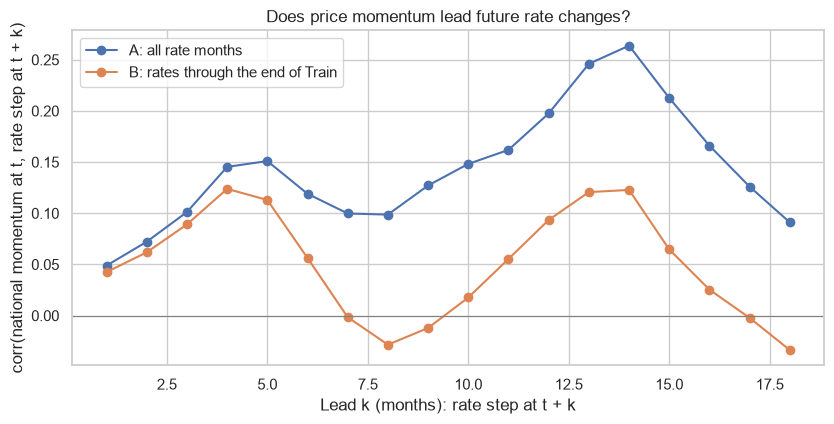

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for variant, g in sweep.groupby("variant"):
    ax.plot(g["lag_months"], g["correlation"], marker="o", label=variant)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Lead k (months): rate step at t + k")
ax.set_ylabel("corr(national momentum at t, rate step at t + k)")
ax.set_title("Does price momentum lead future rate changes?")
ax.legend()
fig.tight_layout()
fig.savefig("../outputs/phase3b_reverse_causation_leads.png", dpi=150)
plt.show()

## 3. How much of variant A comes from the latest months?

Variant A and variant B differ only in the latest momentum months, whose rate steps fall **after** the end of Train. Looking at the 14-month lead, which pairs do those months account for?

In [4]:
pairs = pd.read_sql(
    """
    SELECT variant, lag_months, momentum_month, rate_month, mom_3m, rate_step_1m
    FROM reverse_causation_pairs ORDER BY variant, lag_months, momentum_month
    """, engine)
pairs["momentum_month"] = pd.to_datetime(pairs["momentum_month"])
pairs["rate_month"] = pd.to_datetime(pairs["rate_month"])

a14 = pairs[(pairs["variant"].str.startswith("A")) & (pairs["lag_months"] == 14)]
b14 = pairs[(pairs["variant"].str.startswith("B")) & (pairs["lag_months"] == 14)]
extra = a14[~a14["momentum_month"].isin(b14["momentum_month"])]
print(f"Lead 14: variant A has {len(a14)} pairs, variant B has {len(b14)}. {len(extra)} pairs only exist in A:")
print(f"  momentum months {extra['momentum_month'].min().date()} to {extra['momentum_month'].max().date()}, "
      f"paired with rate steps in {extra['rate_month'].min().date()} to {extra['rate_month'].max().date()}")
print(f"  correlation with them (A): {a14['mom_3m'].corr(a14['rate_step_1m']):.4f}")
print(f"  correlation without them (B): {b14['mom_3m'].corr(b14['rate_step_1m']):.4f}")

Lead 14: variant A has 258 pairs, variant B has 244. 14 pairs only exist in A:
  momentum months 2020-08-31 to 2021-09-30, paired with rate steps in 2021-10-31 to 2022-11-30
  correlation with them (A): 0.2637
  correlation without them (B): 0.1228


Those 14 momentum months are paired with the sharp 2022 rate rise, and they alone move the correlation from 0.12 to 0.26. The 14-month peak of variant A therefore rests partly on one episode.

## 4. Do neighbouring months resemble each other?

Each national momentum value is a 3-month change, so neighbouring values share two of their three months. The autocorrelation of the momentum series shows how strongly consecutive months resemble each other, which is what an interval that treats months as independent ignores.

In [5]:
mom = pairs[(pairs["variant"].str.startswith("A")) & (pairs["lag_months"] == 1)].set_index("momentum_month")["mom_3m"]
print(f"Autocorrelation of national 3-month momentum, 1 month apart: {mom.autocorr(1):.2f}")
print(f"Autocorrelation 3 months apart: {mom.autocorr(3):.2f}")
print(f"Number of months: {len(mom)}")

Autocorrelation of national 3-month momentum, 1 month apart: 0.92
Autocorrelation 3 months apart: 0.68
Number of months: 258


## 5. Block bootstrap

Instead of treating each month as independent, resample **runs of 12 consecutive months** with replacement, 2,000 times, and recompute the correlation each time. The spread of those correlations gives an interval that respects the dependence between neighbouring months. The table also tries 6- and 24-month blocks, to show that the answer does not hinge on the block length.

In [6]:
rows = []
for (variant, lag), g in pairs.groupby(["variant", "lag_months"]):
    g = g.sort_values("momentum_month")
    x, y = g["mom_3m"].to_numpy(), g["rate_step_1m"].to_numpy()
    lo, hi = block_bootstrap_ci(x, y, block=12)
    rows.append({"variant": variant, "lag_months": lag, "correlation": np.corrcoef(x, y)[0, 1],
                 "n_rows": len(g), "block_ci_low": lo, "block_ci_high": hi})
boot = add_inference(pd.DataFrame(rows))
boot["block_ci_includes_zero"] = (boot["block_ci_low"] < 0) & (boot["block_ci_high"] > 0)
print("Leads with a block-bootstrap interval that excludes zero:")
print(boot.loc[~boot["block_ci_includes_zero"], ["variant", "lag_months", "correlation", "block_ci_low", "block_ci_high"]].round(4).to_string(index=False)
      if (~boot["block_ci_includes_zero"]).any() else "  none")
print(f"\nPlain intervals that exclude zero: {int(((boot['ci_low'] > 0) | (boot['ci_high'] < 0)).sum())} of {len(boot)} leads")
print(f"Block-bootstrap intervals that exclude zero: {int((~boot['block_ci_includes_zero']).sum())} of {len(boot)} leads")

Leads with a block-bootstrap interval that excludes zero:
                          variant  lag_months  correlation  block_ci_low  block_ci_high
               A: all rate months           4       0.1453        0.0161         0.2323
               A: all rate months           5       0.1510        0.0134         0.2278
               A: all rate months          12       0.1976        0.0318         0.2903
               A: all rate months          13       0.2460        0.0513         0.3306
               A: all rate months          14       0.2637        0.0544         0.3639
B: rates through the end of Train           4       0.1238        0.0053         0.2224
B: rates through the end of Train          12       0.0934        0.0043         0.1774
B: rates through the end of Train          13       0.1207        0.0233         0.2233
B: rates through the end of Train          14       0.1228        0.0092         0.2358

Plain intervals that exclude zero: 12 of 36 leads
Block-boots

In [7]:
key = [("A: all rate months", 14), ("B: rates through the end of Train", 4), ("B: rates through the end of Train", 14)]
rows = []
for variant, lag in key:
    g = pairs[(pairs["variant"] == variant) & (pairs["lag_months"] == lag)].sort_values("momentum_month")
    x, y = g["mom_3m"].to_numpy(), g["rate_step_1m"].to_numpy()
    plain = add_inference(pd.DataFrame({"correlation": [np.corrcoef(x, y)[0, 1]], "n_rows": [len(g)]})).iloc[0]
    row = {"variant": variant, "lead": lag, "r": plain["correlation"], "n": len(g),
           "plain 95% CI": f"[{plain['ci_low']:.3f}, {plain['ci_high']:.3f}]"}
    for block in (6, 12, 24):
        lo, hi = block_bootstrap_ci(x, y, block=block)
        row[f"block {block}"] = f"[{lo:.3f}, {hi:.3f}]"
    rows.append(row)
pd.DataFrame(rows)

,variant,lead,r,n,plain 95% CI,block 6,block 12,block 24
0,A: all rate months,14,0.263734,258,"[0.146, 0.374]","[0.062, 0.373]","[0.054, 0.364]","[0.044, 0.332]"
1,B: rates through the end of Train,4,0.123815,254,"[0.001, 0.243]","[-0.001, 0.244]","[0.005, 0.222]","[-0.001, 0.238]"
2,B: rates through the end of Train,14,0.122789,244,"[-0.003, 0.245]","[0.006, 0.240]","[0.009, 0.236]","[0.012, 0.250]"


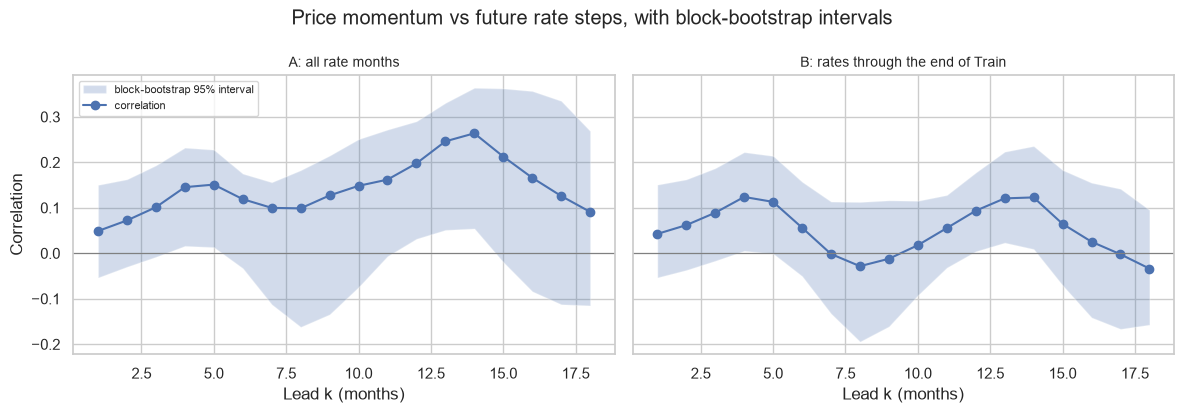

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (variant, g) in zip(axes, boot.groupby("variant")):
    ax.fill_between(g["lag_months"], g["block_ci_low"], g["block_ci_high"], alpha=0.25, label="block-bootstrap 95% interval")
    ax.plot(g["lag_months"], g["correlation"], marker="o", label="correlation")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_title(variant, fontsize=10)
    ax.set_xlabel("Lead k (months)")
axes[0].set_ylabel("Correlation")
axes[0].legend(fontsize=8)
fig.suptitle("Price momentum vs future rate steps, with block-bootstrap intervals")
fig.tight_layout()
fig.savefig("../outputs/phase3b_reverse_causation_bootstrap.png", dpi=150)
plt.show()

**Reading the results**

- With 12-month blocks, 9 of the 36 leads have an interval that excludes zero, against 12 of 36 with plain intervals. The block bootstrap is a little more cautious overall, but it does not remove the signal, and its intervals are not much wider than the plain ones.
- **Variant A at 14 months** stays clearly positive in every version: the lower bound is between 0.044 and 0.062 for blocks of 6 to 24 months.
- **Variant B**, which uses no rate data after Train, is borderline. At 4 months the interval includes zero for blocks of 6 and 24 months and only just excludes it for 12 months. At 14 months it excludes zero for all three block lengths, although the plain interval includes zero.
- The block length barely changes the intervals between 6 and 24 months, which is reassuring. But series that move over multi-year cycles may need much longer blocks than the 24 months tried here, so the intervals could still be too optimistic.

## 6. Save the results

In [9]:
boot.to_csv("../outputs/phase3b_reverse_causation.csv", index=False)
print("Saved outputs/phase3b_reverse_causation.csv and two figures")

Saved outputs/phase3b_reverse_causation.csv and two figures


## 7. Findings

Conclusion: **at most weak evidence that home prices lead mortgage rates.**

- **The strongest lead depends on the variant.** Variant A (all rate months) peaks at 14 months with r = 0.2637 (n = 258). Variant B (rate steps up to the end of Train) roughly halves it: r = 0.1228 at 14 months (n = 244), and its strongest lead is 4 months (r = 0.1238, n = 254).
- **One episode lifts the 14-month peak.** The 14 latest momentum months (2020-08 to 2021-09), paired with the sharp rate rise of 2021-10 to 2022-11, are the only difference between A and B at that lead (Section 3).
- **A block bootstrap gives intervals of similar width to the plain ones.** With 12-month blocks, 9 of the 36 leads have an interval that excludes zero, against 12 of 36 with plain intervals. In variant B, leads 4, 12, 13 and 14 exclude zero, but only barely (lower bounds between 0.004 and 0.023), and the 4-month result includes zero with blocks of 6 or 24 months. So there are small positive correlations, about 0.1 on Train-only data, at leads around 4 and 12 to 14 months.
- **Why this is not reliable evidence.** The correlations depend on the variant and on the lead, 36 leads are tried at once without any correction for it, and even the longest blocks tried (24 months) may be too short for series that move over multi-year cycles, so the intervals can still overstate the precision.
- **The sign mismatch in notebook 03 stays only partly explained.** If prices lead rates, falling prices followed by falling rates could contribute to the negative link between the rate change and later declines. This check gives that explanation weak support at most.